# Step Out Buffalo Halloween Houses

Create an interactive HTML map and a PNG overview of the Halloween displays in the Buffalo area. Run the cells from top to bottom; the source CSV and the supplied marker image and font should remain beside this notebook.

In [35]:
import base64
import csv
import html
import json
import math
from io import BytesIO
from pathlib import Path
from urllib.parse import parse_qs, urlsplit

import requests
from PIL import Image

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "halloween_houses_with_coordinates.csv"
MARKER_PATH = PROJECT_DIR / "haunted-house.png"
FONT_PATH = PROJECT_DIR / "SpookyScary-4n5J4.otf"
HTML_PATH = PROJECT_DIR / "step_out_buffalo_halloween_houses.html"
PNG_PATH = PROJECT_DIR / "step_out_buffalo_halloween_houses.png"

required_columns = {
    "location_name", "address", "viewing_hours", "latitude", "longitude", "site_url"
}
with DATA_PATH.open(encoding="utf-8-sig", newline="") as csv_file:
    reader = csv.DictReader(csv_file)
    missing_columns = required_columns.difference(reader.fieldnames or [])
    if missing_columns:
        raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")
    houses = list(reader)

if not houses:
    raise ValueError(f"No house locations were found in {DATA_PATH}")

for row in houses:
    row["latitude"] = float(row["latitude"])
    row["longitude"] = float(row["longitude"])
    if not -90 <= row["latitude"] <= 90 or not -180 <= row["longitude"] <= 180:
        raise ValueError(f"Invalid coordinates for {row['location_name']!r}")
    if urlsplit(row["site_url"]).scheme not in {"http", "https"}:
        raise ValueError(f"Invalid website URL for {row['location_name']!r}")

for asset_path in (MARKER_PATH, FONT_PATH):
    if not asset_path.is_file():
        raise FileNotFoundError(f"Required asset not found: {asset_path}")

print(f"Loaded {len(houses)} Halloween house locations.")

Loaded 20 Halloween house locations.


## Build the interactive HTML map

The provided Mapbox WMTS style endpoint is converted to its raster XYZ tile endpoint for Leaflet. The marker and font are embedded in the HTML so the custom popup and icon do not depend on local asset paths.

In [ ]:
MAPBOX_WMTS_URL = (
  "Your Mapbox WMTS URL here"
)
mapbox_style_endpoint = MAPBOX_WMTS_URL.split("/wmts?", maxsplit=1)[0]
mapbox_token = parse_qs(urlsplit(MAPBOX_WMTS_URL).query)["access_token"][0]
mapbox_tiles_url = (
    f"{mapbox_style_endpoint}/tiles/256/{{z}}/{{x}}/{{y}}"
    f"?access_token={mapbox_token}"
)

def data_uri(path, media_type):
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    return f"data:{media_type};base64,{encoded}"

marker_uri = data_uri(MARKER_PATH, "image/png")
font_uri = data_uri(FONT_PATH, "font/otf")
popup_markers = []
for row in houses:
    details = [row["location_name"], row["address"], row["viewing_hours"]]
    detail_lines = "".join(
        f"<div>{html.escape(value)}</div>" for value in details
    )
    link = (
        f'<a href="{html.escape(row["site_url"], quote=True)}" '
        'target="_blank" rel="noopener noreferrer">'
        "Step Out Buffallo Halloween</a>"
    )
    popup_html = (
        '<div class="spooky-popup">'
        f"{detail_lines}<div>{link}</div>"
        "</div>"
    )
    popup_markers.append({
        "latitude": row["latitude"],
        "longitude": row["longitude"],
        "popup": popup_html,
    })

markers_json = json.dumps(popup_markers, ensure_ascii=False).replace("</", "<\\/")
html_document = f'''<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Step Out Buffalo Halloween Houses</title>
  <link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css" integrity="sha256-p4NxAoJBhIIN+hmNHrzRCf9tD/miZyoHS5obTRR9BMY=" crossorigin="">
  <style>
    @font-face {{ font-family: SpookyScary; src: url('{font_uri}') format('opentype'); }}
    html, body {{ height: 100%; margin: 0; background: #090909; }}
    body {{ display: flex; flex-direction: column; color: #ff7518; }}
    header {{ padding: 10px 16px; text-align: center; font: 24px SpookyScary, sans-serif; }}
    #map {{ flex: 1; min-height: 300px; }}
    .spooky-popup {{ box-sizing: border-box; min-width: 210px; padding: 10px 12px; background: #000; color: #ff7518; text-align: center; font: 16px/1.5 SpookyScary, sans-serif; }}
    .spooky-popup a {{ color: #ff7518; }}
    .leaflet-popup-content-wrapper {{ padding: 0; overflow: hidden; background: #000; color: #ff7518; border: 2px solid #ff7518; border-radius: 8px; }}
    .leaflet-popup-content {{ margin: 0; }}
    .leaflet-popup-tip {{ background: #000; box-shadow: 2px 2px 0 #ff7518; }}
  </style>
</head>
<body>
  <header>Step Out Buffalo Halloween Houses</header>
  <div id="map" aria-label="Map of Halloween houses around Buffalo, New York"></div>
  <script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js" integrity="sha256-20nQCchB9co0qIjJZRGuk2/Z9VM+kNiyxNV1lvTlZBo=" crossorigin=""></script>
  <script>
    const houses = {markers_json};
    const map = L.map('map', {{ scrollWheelZoom: true }});
    L.tileLayer({json.dumps(mapbox_tiles_url)}, {{
      maxZoom: 19,
      attribution: '&copy; <a href="https://www.mapbox.com/about/maps/">Mapbox</a> &copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a>'
    }}).addTo(map);
    const houseIcon = L.icon({{
      iconUrl: {json.dumps(marker_uri)},
      iconSize: [44, 44],
      iconAnchor: [22, 40],
      popupAnchor: [0, -38]
    }});
    const bounds = [];
    houses.forEach((house) => {{
      const point = [house.latitude, house.longitude];
      bounds.push(point);
      L.marker(point, {{ icon: houseIcon }}).addTo(map)
        .bindPopup(house.popup, {{ maxWidth: 320 }});
    }});
    map.fitBounds(bounds, {{ padding: [28, 28] }});
  </script>
</body>
</html>
'''
HTML_PATH.write_text(html_document, encoding="utf-8")
print(f"Interactive map saved to: {HTML_PATH}")

Interactive map saved to: c:\Users\nickp\mtb_viz_challenge\halloween\step_out_buffalo_halloween_houses.html


## Export a PNG overview

Fetch a static image from the same Mapbox style and composite the supplied haunted-house marker at each coordinate. The HTML map remains the interactive version with clickable popups.

In [37]:
map_width, map_height = 1200, 900
map_center_latitude = (min(row["latitude"] for row in houses) + max(row["latitude"] for row in houses)) / 2
map_center_longitude = (min(row["longitude"] for row in houses) + max(row["longitude"] for row in houses)) / 2
static_zoom = 11
static_map_url = (
    f"{mapbox_style_endpoint}/static/"
    f"{map_center_longitude},{map_center_latitude},{static_zoom},0/"
    f"{map_width}x{map_height}?access_token={mapbox_token}"
)
response = requests.get(static_map_url, timeout=60)
response.raise_for_status()
map_image = Image.open(BytesIO(response.content)).convert("RGBA")
if map_image.size != (map_width, map_height):
    raise ValueError(f"Unexpected static map image size: {map_image.size}")

icon = Image.open(MARKER_PATH).convert("RGBA")
icon.thumbnail((32, 32), Image.Resampling.LANCZOS)
world_pixels = 512 * (2 ** static_zoom)

def mercator_pixel(latitude, longitude):
    latitude = max(min(latitude, 85.05112878), -85.05112878)
    x = (longitude + 180) / 360 * world_pixels
    latitude_radians = math.radians(latitude)
    y = (
        1 - math.asinh(math.tan(latitude_radians)) / math.pi
    ) / 2 * world_pixels
    return x, y

center_x, center_y = mercator_pixel(map_center_latitude, map_center_longitude)
for row in houses:
    point_x, point_y = mercator_pixel(row["latitude"], row["longitude"])
    pixel_x = round(map_width / 2 + point_x - center_x)
    pixel_y = round(map_height / 2 + point_y - center_y)
    map_image.alpha_composite(icon, (pixel_x - icon.width // 2, pixel_y - icon.height))

map_image.convert("RGB").save(PNG_PATH, format="PNG", optimize=True)
print(f"PNG map saved to: {PNG_PATH}")

PNG map saved to: c:\Users\nickp\mtb_viz_challenge\halloween\step_out_buffalo_halloween_houses.png


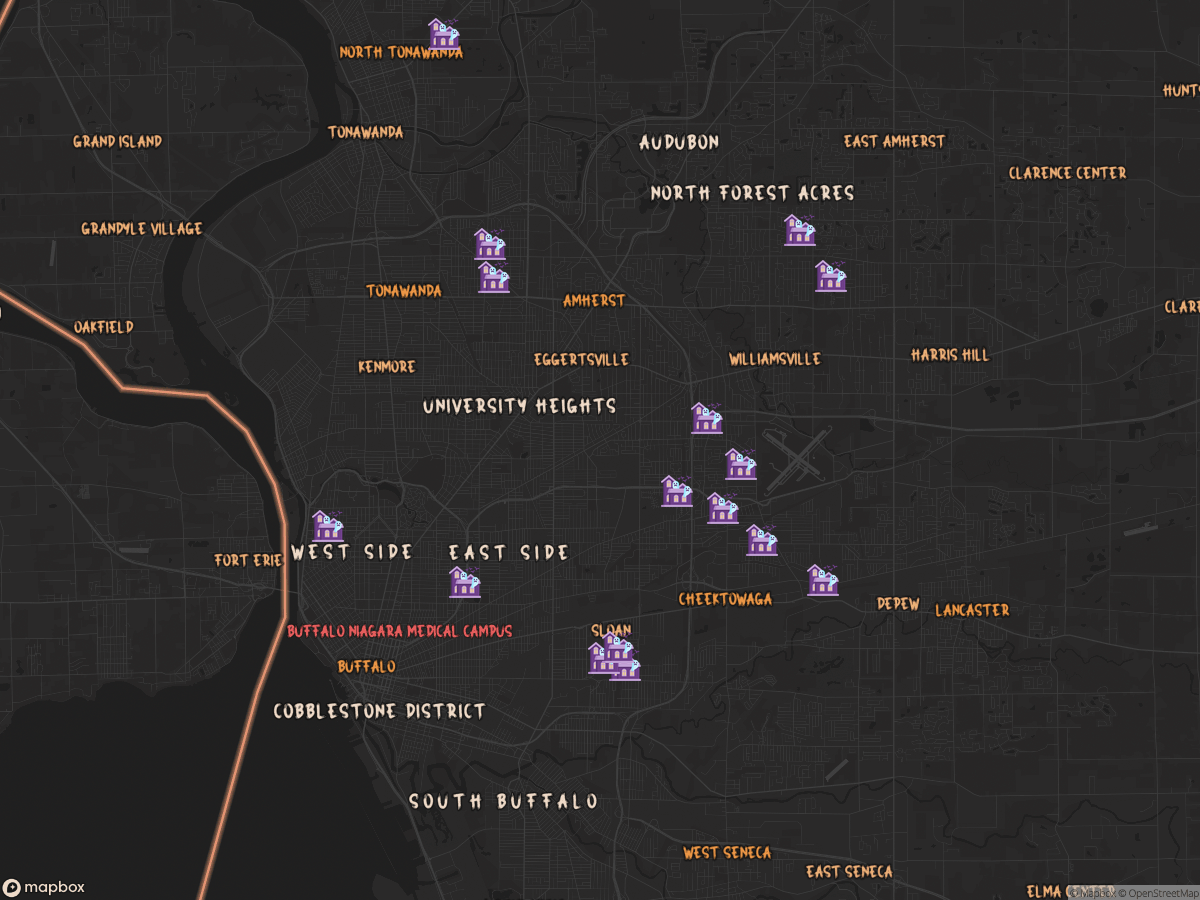

In [38]:
from IPython.display import HTML, Image as NotebookImage, display

display(HTML(f'<a href="{HTML_PATH.name}" target="_blank">Open the interactive HTML map</a>'))
display(NotebookImage(filename=str(PNG_PATH)))